# Study 2 with the mixed model

Study 2 (KnowQA) tests the correctness model on readers whose knowledge we control: each answer was
given under **no knowledge** (no context, so a correct answer is a guess), **partial knowledge** (the
paragraph to read, as in Study 1) or **full knowledge** (the correct answer's content shown first),
and after every answer the participant rated their confidence from 1 to 5.

This notebook repeats the model half of `../knowledge_regimes/overview.ipynb` with the mixed model
(`modeling/models/glmm_model.py`) in place of the logistic regression: fitted once on all of Study 1,
applied to every Study 2 trial, scored on each regime, and set against the confidence rating. The
descriptions of the data themselves (accuracy, pace and confidence by regime, the items guessed
right, LexTALE, the sittings) do not involve a model, so they are not repeated; they are in that
notebook.

**How a Study 2 trial is scored.** Every Study 2 participant is new, so their random intercept is 0.
Every Study 2 item is also a Study 1 item, so the item's Study 1 intercept could be carried over;
sections 1 to 3 do not, scoring on the fixed effects alone (`glmm_fixed`), which keeps them
comparable with the logistic regression. Section 4 adds the item intercepts.

It needs Julia (`src/vendor/julia_integration/julia_test.ipynb`). It runs in about three minutes.
The participants are too few for any comparison between people, so the per-person figures show
patterns, not tests. The model keeps Study 1's scaling: every feature is standardised with Study 1's
means and SDs. This notebook only shows; it saves nothing.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import contextlib
import io

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import src.config.columns as Con
from src.config.datasets import dataset, KNOW_QA_IA_ANSWERS_PATH
from src.features.build import load_model_ready
from src.modeling.models.glmm_model import TrialLevelJuliaGLMERModel   # starts Julia
import src.analyses.correctness_prediction.knowledge_regimes.descriptives as D
from src.analyses.correctness_prediction.knowledge_regimes.comparison_runs import (
    run_regime_split_comparison,
)
from src.analyses.correctness_prediction.knowledge_regimes.confidence_correlation import (
    correlations_by_participant,
    model_vs_correctness_by_run,
    partial_correlations_by_participant,
    partial_correlations_by_run,
    run_confidence_correlation,
)
from src.analyses.correctness_prediction.mixed_model.run import fit_report

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Study 2's tables, named once and passed to every call: `comparison_runs` and
# `confidence_correlation` default to the first pilot (3 people), not to KnowQA.
KNOWQA_FEATURES = dataset("knowqa").model_ready    # one row per trial
KNOWQA_IA_REPORT = KNOW_QA_IA_ANSWERS_PATH         # cleaned IA report: regime, session, confidence
l1 = load_model_ready(dataset("l1").model_ready)   # Study 1, the training data

df = D.load_showcase_frame(KNOWQA_FEATURES, KNOWQA_IA_REPORT)
print(f"Study 1: {len(l1):,} trials   Study 2: {len(df):,} trials, "
      f"{df[Con.PARTICIPANT_ID].nunique()} participants")


def glmm(predict_with="fixed"):
    # A maker of unfitted mixed models, for the functions that take `model_builder`.
    return lambda: TrialLevelJuliaGLMERModel(name=f"glmm_{predict_with}", predict_with=predict_with)

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


KnowQA showcase frame: 1885 trials x 201 columns
  participants : 13
  sessions     : 39
  regimes      : {'full knowledge': 640, 'no knowledge': 625, 'partial knowledge': 620}
Study 1: 19,436 trials   Study 2: 1,885 trials, 13 participants


## 1. The Study 1 model, fitted once and applied to every trial
*`descriptives.fit_l1_model`, `descriptives.attach_predictions`*

`fit_l1_model` fits the mixed model on every Study 1 trial, with nothing held out, on the same 12
features as the logistic regression. `attach_predictions` then adds, to every Study 2 trial, the
predicted probability that the answer is correct (`pred_prob`) and its predicted label. It first
prints how many feature cells are filled with 0 because they are empty; that fill is a stated
modelling choice, not a measurement. The fit report below says how the fit ended and how large the
random intercepts are.

In [2]:
model = D.fit_l1_model(l1, model_builder=glmm("fixed"))
display(pd.Series(fit_report(model)).to_frame("glmm_fixed"))
df = D.attach_predictions(df, model)

fitted glmm_fixed on 19436 L1 trials, 12 features
  L1 base rate: 0.8407


,glmm_fixed
formula,is_correct ~ 1 + area_dwell_proportion__correc...
class_weight,balanced
predict_with,fixed
optimizer_returnvalue,FTOL_REACHED
converged,True
is_singular,False
n_train,19436
sd__text_id_with_q__(Intercept),1.614913
sd__participant_id__(Intercept),0.913403


imputed with fill_value=0.0: 11 cell(s) = 0.049% of the KnowQA feature matrix
    mean_max_fix_pupil_size_z__correct: 11 (0.58% of trials)


### How well it transfers

One row per regime, after all trials pooled. Read `balanced_accuracy` (the mean of sensitivity and
specificity), not `accuracy`: the share of correct answers runs from about a third under no
knowledge to nearly all under full knowledge, and plain accuracy largely repeats it. In the figure
the dashed line is that share, the score of always predicting "correct". Under full knowledge there
are only a handful of wrong answers, so its specificity rests on very few trials.

The first table puts the mixed model's balanced accuracy beside the logistic regression's, fitted
and scored the same way.

,logreg,glmm_fixed
regime,,
all,0.806,0.812
no knowledge,0.777,0.806
partial knowledge,0.774,0.785
full knowledge,0.861,0.857


,regime,n,n_correct,n_wrong,accuracy,balanced_accuracy,sensitivity,specificity,TP,TN,FP,FN,FN_over_FP,model_family
0,all,1885,1352,533,0.811,0.812,0.810,0.814,1095,434,99,257,2.596,glmm
1,no knowledge,625,232,393,0.810,0.806,0.793,0.819,184,322,71,48,0.676,glmm
2,partial knowledge,620,496,124,0.782,0.785,0.780,0.790,387,98,26,109,4.192,glmm
3,full knowledge,640,624,16,0.841,0.857,0.840,0.875,524,14,2,100,50.000,glmm


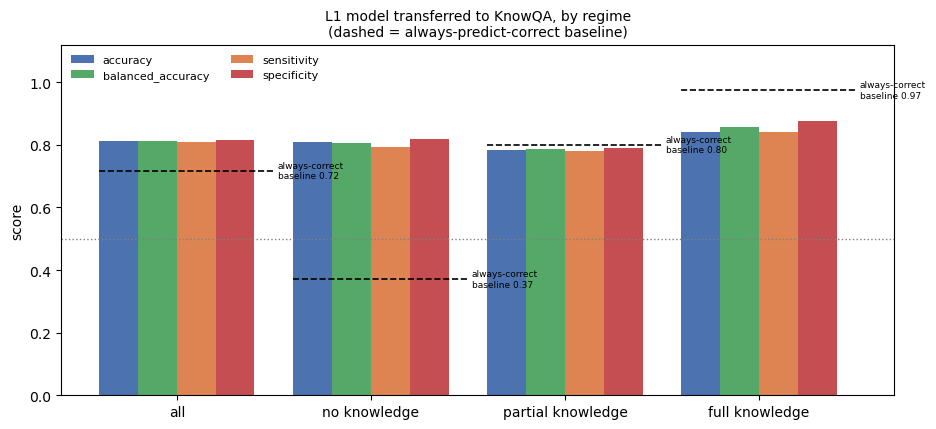

In [3]:
logreg_scored = D.attach_predictions(df, D.fit_l1_model(l1, verbose=False), verbose=False)
metrics = D.prediction_metrics_by_regime(df)
display(pd.DataFrame({
    "logreg": D.prediction_metrics_by_regime(logreg_scored).set_index(D.REGIME_COL)["balanced_accuracy"],
    "glmm_fixed": metrics.set_index(D.REGIME_COL)["balanced_accuracy"],
}).round(3))
display(metrics.round(3))
D.plot_transfer_metrics(metrics, save=False);

One confusion matrix per regime, shaded by the share of each actual outcome, with the counts
printed. The top-left share is the specificity (wrong answers predicted wrong), the bottom-right the
sensitivity (correct answers predicted correct).

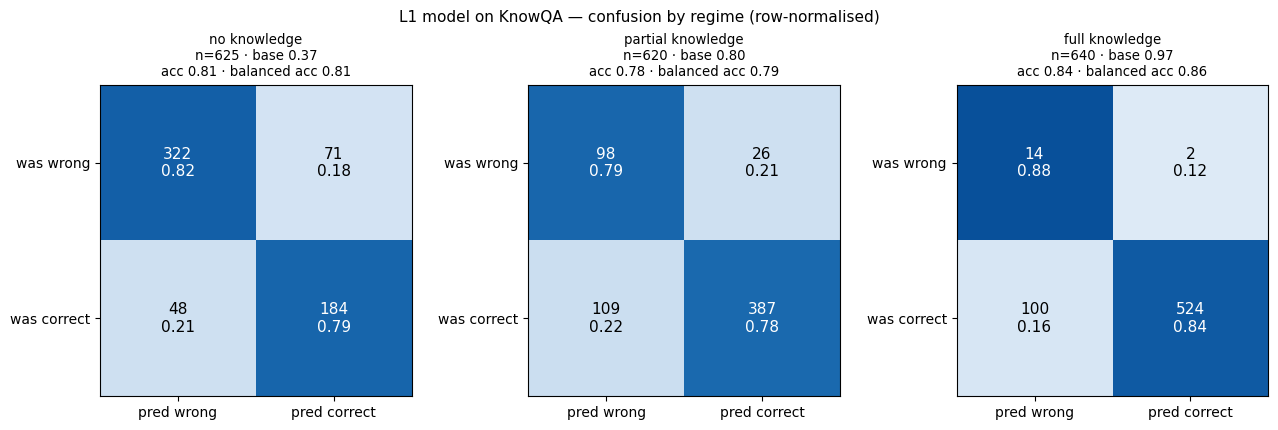

In [4]:
D.plot_confusion_by_regime(df, save=False);

### What probabilities it gives

The study's central prediction: high probabilities under full knowledge, low under no knowledge,
*including* on the no-knowledge answers that happened to be right, because the model reads
behaviour rather than the outcome. Compare the boxes for correct answers across regimes: lucky
guesses should sit lower than correct answers given with full knowledge. `mean_prob_correct` in the
table is the same comparison in numbers.

,regime,n,mean_prob,median_prob,sd_prob,n_correct,mean_prob_correct,n_wrong,mean_prob_wrong,model_family
0,all,1885,0.638,0.798,0.364,1352,0.785,533,0.263,glmm
1,no knowledge,625,0.439,0.334,0.365,232,0.750,393,0.255,glmm
2,partial knowledge,620,0.663,0.819,0.341,496,0.755,124,0.292,glmm
3,full knowledge,640,0.807,0.962,0.280,624,0.822,16,0.244,glmm


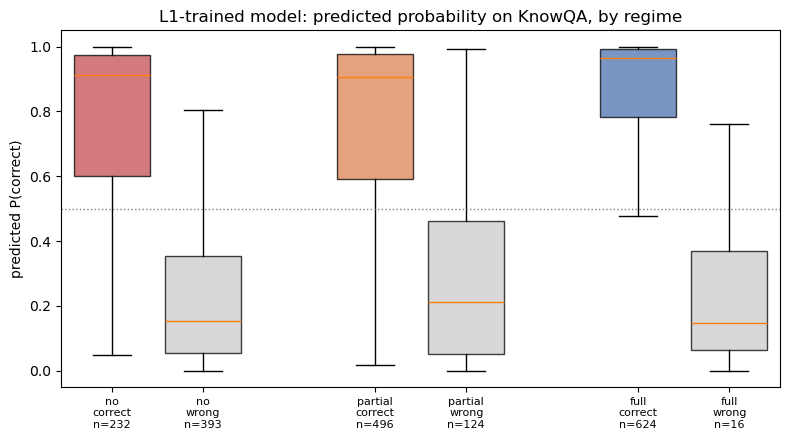

In [5]:
display(D.probability_by_regime(df).round(3))
D.plot_probability_by_regime(df, save=False);

The same probabilities as histograms, one panel per regime, split into correct and wrong answers;
the dashed line is the regime's mean. Where the two humps sit apart, the model separates right from
wrong *within* the regime, not only by following its share of correct answers.

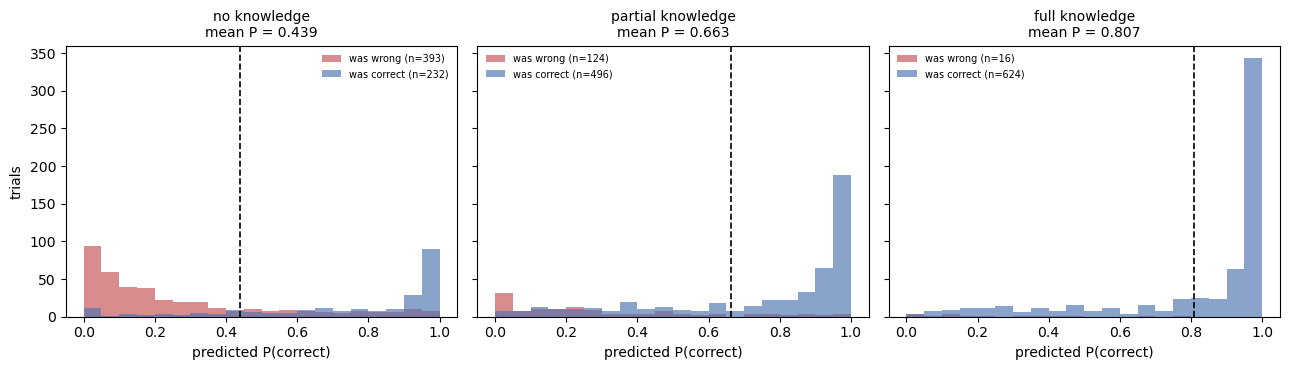

In [6]:
D.plot_probability_histograms(df, save=False);

### The model against the confidence rating

Which tells right from wrong answers apart better, the model or the participant's own rating? Both
are scored the same way, by the AUC for predicting a correct answer, on the same trials.
`auc_combined` averages the two ranks: if it beats both, they carry different information.

,regime,n,n_correct,auc_model,auc_confidence,auc_combined,model_minus_confidence,model_family
0,all,1885,1352,0.893,0.836,0.928,0.058,glmm
1,no knowledge,625,232,0.875,0.517,0.776,0.357,glmm
2,partial knowledge,620,496,0.863,0.777,0.881,0.086,glmm
3,full knowledge,640,624,0.929,0.757,0.918,0.173,glmm


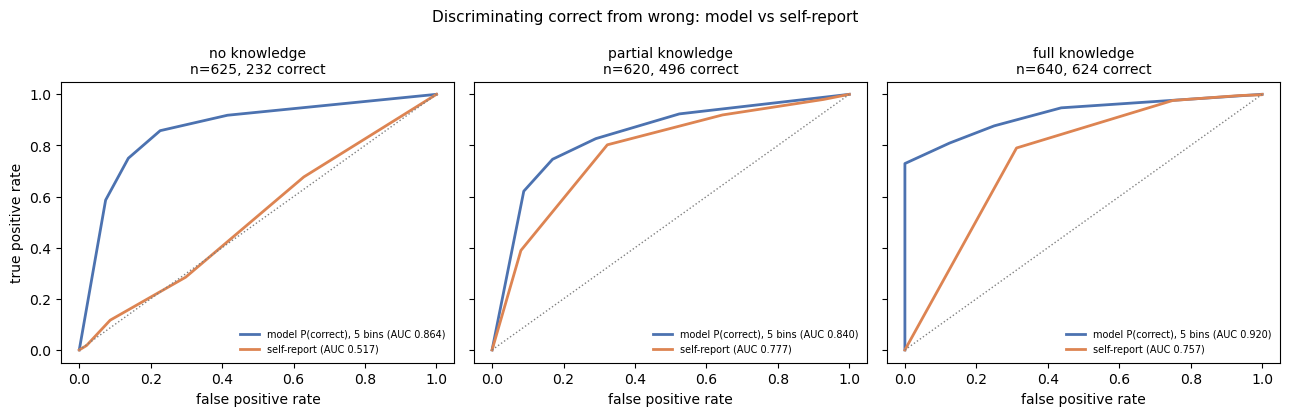

In [7]:
display(D.discrimination_comparison(df).round(3))
D.plot_discrimination_roc(df, save=False);

Is the model's lead more than noise? `discrimination_bootstrap` resamples whole participants, 2,000
times, and scores both AUCs on the same resampled trials each time; the model's probability is cut
into the same five bins as in the curves above. Read the right panel: the two AUCs come from the same
trials, so whether their intervals overlap on the left says little. The same items recur across
participants and that is not resampled, and there are few participants to resample, so the
intervals are probably somewhat too narrow.

,regime,auc_model,auc_confidence,diff,diff_ci_low,diff_ci_high,p,n_boot_ok
0,no knowledge,0.8642,0.5174,0.3468,0.2740,0.4140,0.0005,2000
1,partial knowledge,0.8400,0.7774,0.0626,0.0179,0.1177,0.0040,2000
2,full knowledge,0.9201,0.7569,0.1633,0.0821,0.2611,0.0005,2000


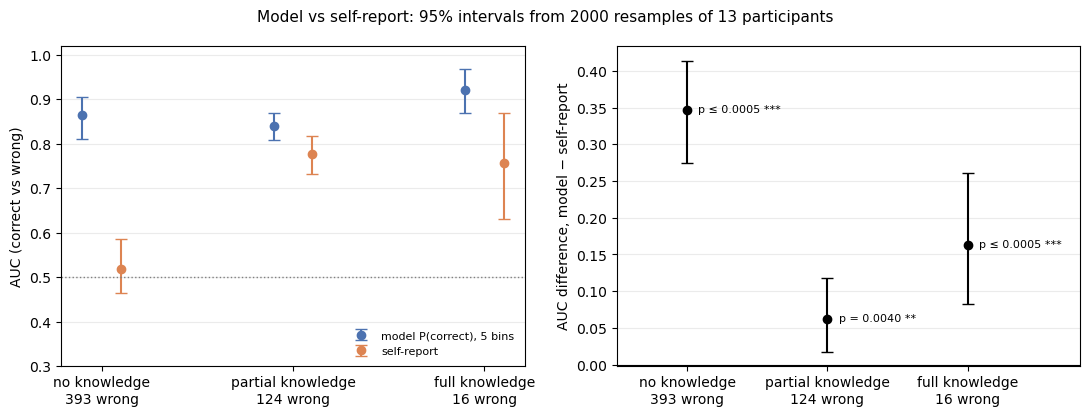

In [8]:
boot = D.discrimination_bootstrap(df)   # about 15 s: 2,000 resamples per regime
display(boot[[D.REGIME_COL, "auc_model", "auc_confidence", "diff", "diff_ci_low", "diff_ci_high",
              "p", "n_boot_ok"]].round(4))
D.plot_discrimination_bootstrap(boot, save=False);

### Per participant

Per participant and regime: their own accuracy, their mean confidence, the model's mean predicted
probability and the model's balanced accuracy. Where a participant made no errors in a regime,
balanced accuracy is undefined, and the cell shows the model's plain accuracy with a star. The
narrow left panel is each participant's English proficiency score (LexTALE).

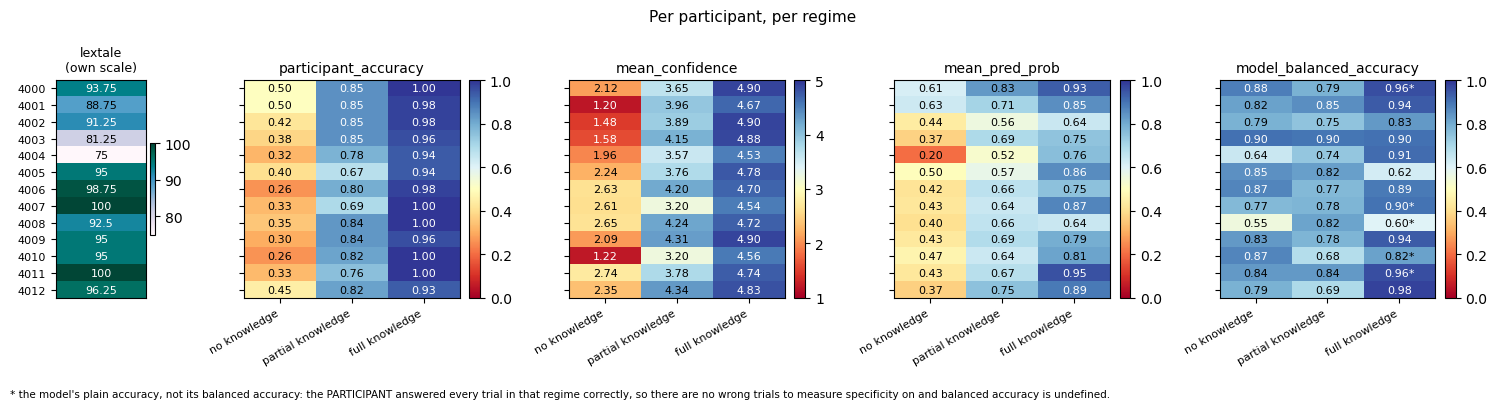

In [9]:
df = D.attach_lextale(df)
D.plot_participant_regime_heatmap(df, side_column="lextale", figsize=(15, 3.8), save=False);

The same per-participant numbers as lines, one per regime: is someone low everywhere, or in one
regime only, and do their confidence and the model's probability move together?

,participant_id,regime,n,n_wrong,participant_accuracy,mean_confidence,median_RT_ms,mean_seq_len,mean_pred_prob,model_accuracy,model_balanced_accuracy,model_sensitivity,model_specificity,auc_model,auc_confidence,model_family
0,4000,full knowledge,49,0,1.000,4.898,2729.0,5.286,0.935,0.959,NaN,0.959,NaN,NaN,NaN,glmm
1,4000,no knowledge,50,25,0.500,2.120,6379.0,8.060,0.615,0.880,0.880,1.000,0.760,0.970,0.706,glmm
2,4000,partial knowledge,46,7,0.848,3.652,4231.5,7.196,0.833,0.935,0.786,1.000,0.571,0.945,0.835,glmm
3,4001,full knowledge,49,1,0.980,4.673,5395.0,5.878,0.852,0.878,0.938,0.875,1.000,0.917,0.844,glmm
4,4001,no knowledge,50,25,0.500,1.200,12432.0,9.340,0.633,0.820,0.820,1.000,0.640,0.930,0.540,glmm
5,4001,partial knowledge,46,7,0.848,3.957,9768.0,7.978,0.711,0.848,0.852,0.846,0.857,0.938,0.780,glmm
6,4002,full knowledge,49,1,0.980,4.898,8867.0,5.816,0.641,0.673,0.833,0.667,1.000,0.938,0.469,glmm
7,4002,no knowledge,50,29,0.420,1.480,12139.0,7.380,0.441,0.800,0.788,0.714,0.862,0.821,0.484,glmm
8,4002,partial knowledge,46,7,0.848,3.891,11766.0,7.826,0.556,0.674,0.749,0.641,0.857,0.777,0.800,glmm
9,4003,full knowledge,49,2,0.959,4.878,8349.0,7.041,0.749,0.816,0.904,0.809,1.000,0.947,0.957,glmm


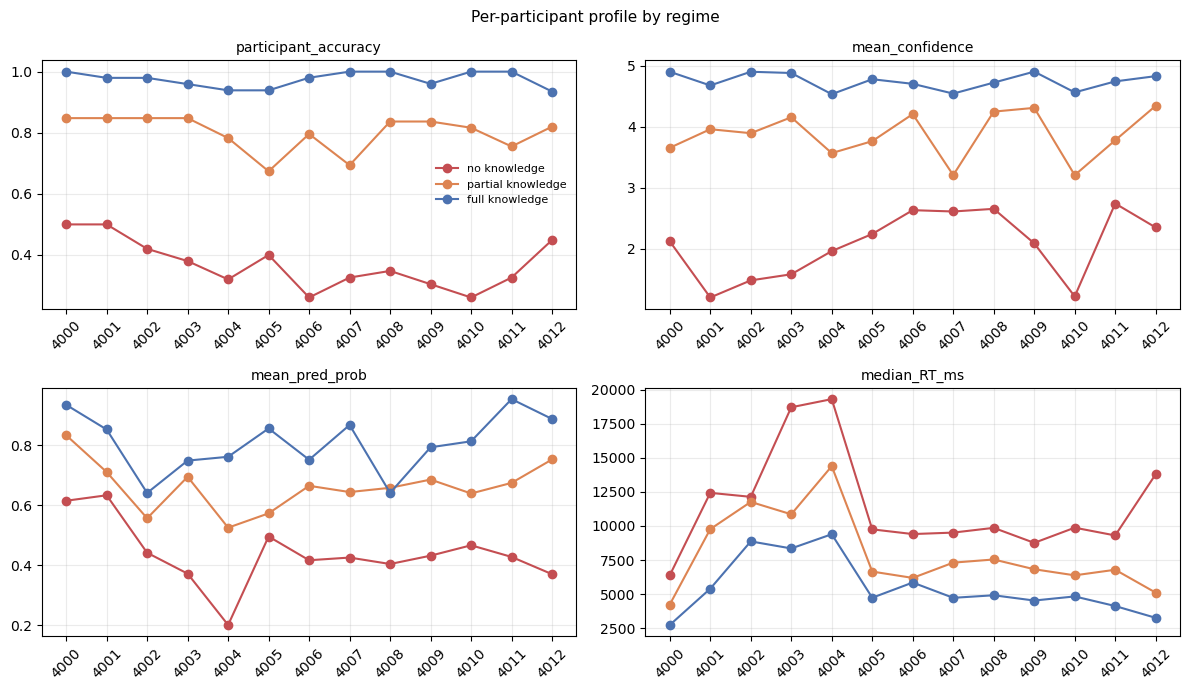

In [10]:
display(D.participant_profile(df).round(3))
D.plot_participant_profiles(df, save=False);

## 2. The Study 1 model scored on each regime as a separate run
*`comparison_runs.run_regime_split_comparison`*

The project's standard train-on-Study-1, test-on-new-data routine, run on the trials of each regime
in turn and on all of them pooled (`all`), with `model_builder` set to the mixed model and its own
intervals (`coef_ci_cluster="cluster"`). Every run fits the same model on the same data, so the runs
differ only in the trials they are scored on. The routine draws six figures per run and prints a
full score report per run; the figures are closed here and only the head of the printout is shown.

In [11]:
log = io.StringIO()
with contextlib.redirect_stdout(log), plt.rc_context({"figure.max_open_warning": 0}):
    regime_result = run_regime_split_comparison(
        train_df=l1,
        new_features=KNOWQA_FEATURES,
        regime_source=KNOWQA_IA_REPORT,
        regimes=D.REGIME_ORDER,
        model_builder=glmm("fixed"),
        coef_ci_cluster="cluster",
        save=False,
    )
plt.close("all")   # the figures the four runs drew; not shown here

lines = log.getvalue().splitlines()
print("\n".join(lines[:10]))
dropped = [line for line in lines if line.startswith("[cross-dataset]")]
print("\n".join(dropped) if dropped else "no feature dropped: KnowQA has all of the model's features")

train (L1): (19436, 219) | test (new): (1885, 200)

new-data trials per regime:
regime
full knowledge       640
no knowledge         625
partial knowledge    620

regimes evaluated: ['no knowledge', 'partial knowledge', 'full knowledge']

no feature dropped: KnowQA has all of the model's features


One row per run. The share of correct answers (`n_positive / n_test`) differs a lot between
regimes, so compare `balanced_accuracy` and `roc_auc` across rows rather than `accuracy`.

In [12]:
regime_result["comparison"].round(3)

,regime,n_test,n_positive,n_negative,accuracy,balanced_accuracy,macro_f1,weighted_f1,f1_class_0,f1_class_1,roc_auc
0,all,1885,1352,533,0.811,0.812,0.785,0.817,0.709,0.860,0.893
1,no knowledge,625,232,393,0.810,0.806,0.800,0.811,0.844,0.756,0.875
2,partial knowledge,620,496,124,0.782,0.785,0.722,0.800,0.592,0.851,0.863
3,full knowledge,640,624,16,0.841,0.857,0.563,0.894,0.215,0.911,0.929


## 3. Confidence against the model's probability
*`confidence_correlation.run_confidence_correlation`*

The per-trial predictions of the section 2 runs (nothing is refitted), each with its confidence
rating. Three questions per run, which can disagree:

* **model vs confidence** (`pred_prob ~ confidence`): does the predicted probability rise with the
  rating? This is the headline.
* **confidence vs correctness** (`is_correct ~ confidence`): does the rating itself track being
  right? Without this reference a weak result for the model cannot be read.
* **within participant**: confidence scales are personal, so a pooled correlation mixes the effect
  inside each person with differences in how people use the scale.

The pooled `all` run repeats every regime's trials, and the regimes differ a lot in both confidence
and accuracy, so read the per-regime rows beside it.

,run,comparison,n,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,all,pred_prob ~ confidence,1885,3.56,0.638,0.450,0.462,2.236201e-100
1,all,is_correct ~ confidence,1885,3.56,0.717,0.546,0.544,1.985124e-145
2,no knowledge,pred_prob ~ confidence,625,2.06,0.439,0.057,0.059,1.374007e-01
3,no knowledge,is_correct ~ confidence,625,2.06,0.371,0.029,0.031,4.457142e-01
4,partial knowledge,pred_prob ~ confidence,620,3.87,0.663,0.403,0.355,7.288514e-20
5,partial knowledge,is_correct ~ confidence,620,3.87,0.800,0.414,0.404,9.647229e-26
6,full knowledge,pred_prob ~ confidence,640,4.74,0.807,0.195,0.170,1.575118e-05
7,full knowledge,is_correct ~ confidence,640,4.74,0.975,0.222,0.192,9.499531e-07


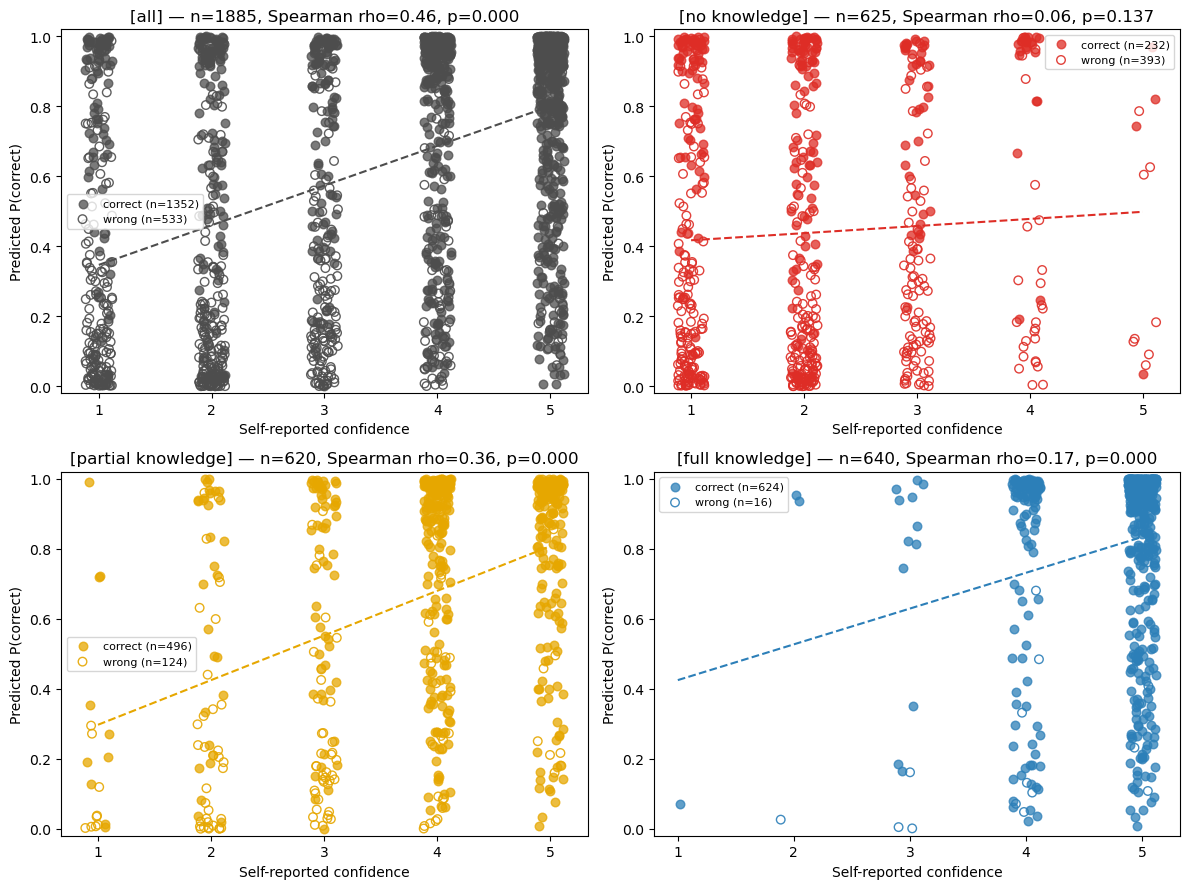

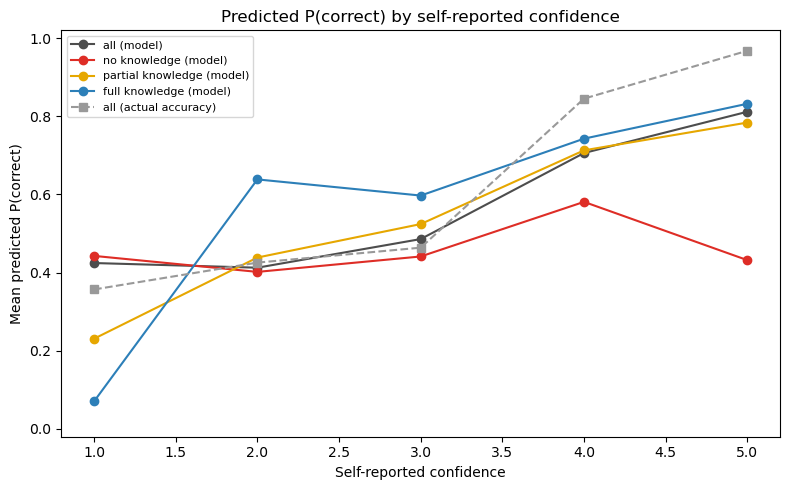

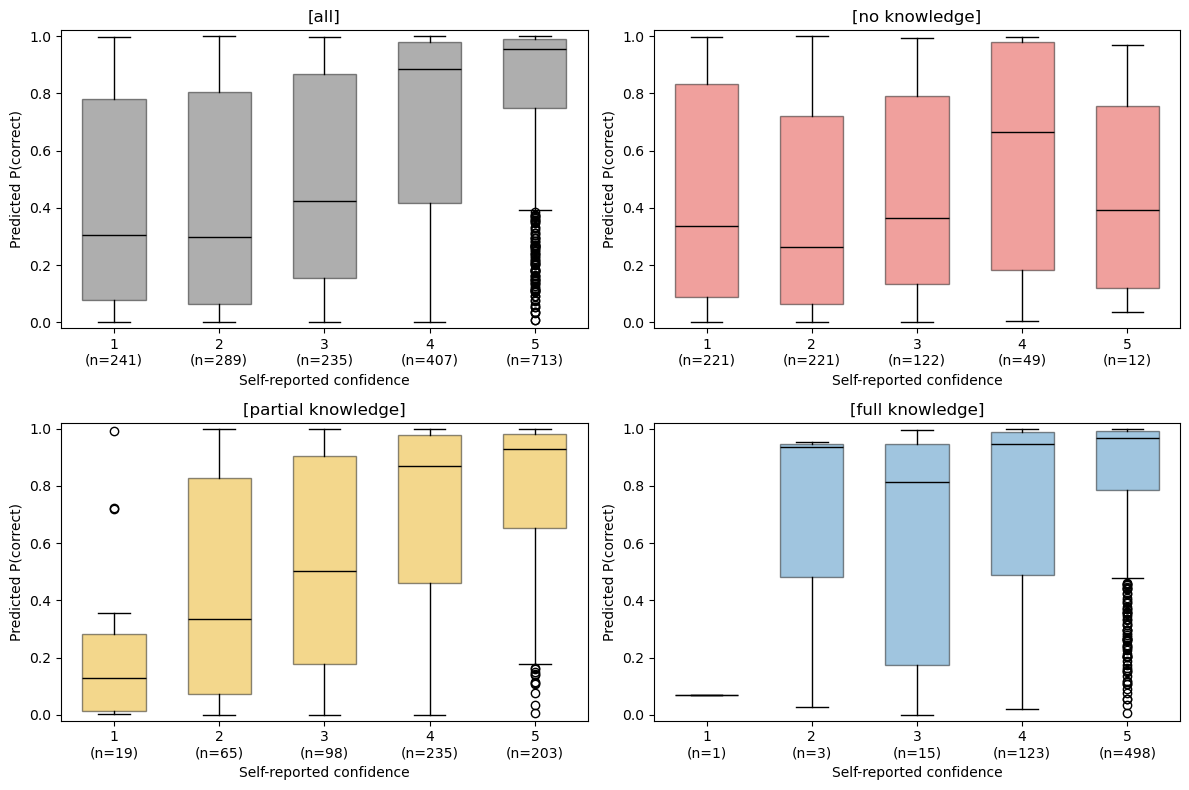

In [13]:
cc = run_confidence_correlation(
    regime_result,
    confidence_source=KNOWQA_IA_REPORT,
    save=False,
    verbose=False,
)
cols = ["run", "comparison", "n", "mean_x", "mean_y", "pearson_r", "spearman_r", "spearman_p"]
display(cc["correlations"][cols].round({"mean_x": 2, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))

The same correlations as bars (Spearman), one cluster per run, with significance stars. Read the two
bars of a cluster together: where the rating itself does not track correctness, a weak bar for the
model is not the model's failure.

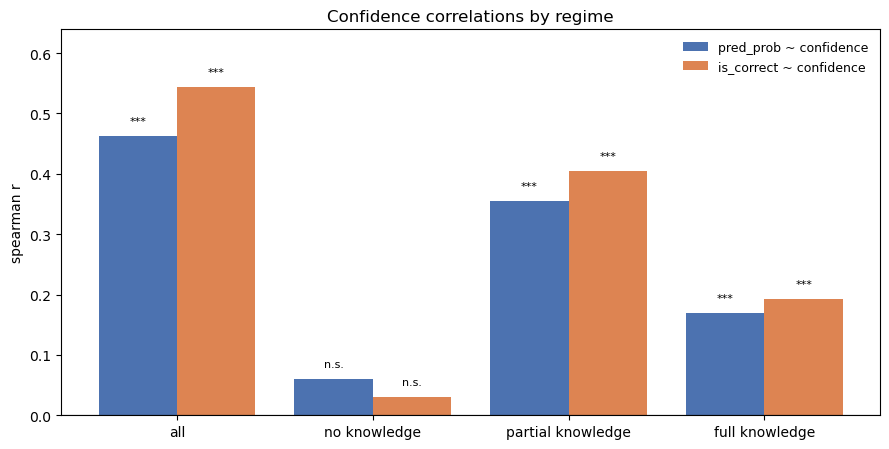

In [14]:
D.plot_correlations_by_run(cc["correlations"], save=False);

With the model against correctness added as a third bar (`pred_prob ~ is_correct`): how well the
model separates correct from wrong answers in each run. A correlation with a 0/1 outcome has a
ceiling below 1 that falls as the share of correct answers moves away from one half, so read the
green bar against that ceiling.

,run,comparison,n,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,all,pred_prob ~ is_correct,1885,0.717,0.638,0.647,0.614,1.951729e-195
1,no knowledge,pred_prob ~ is_correct,625,0.371,0.439,0.656,0.627,1.339627e-69
2,partial knowledge,pred_prob ~ is_correct,620,0.800,0.663,0.543,0.503,4.736007e-41
3,full knowledge,pred_prob ~ is_correct,640,0.975,0.807,0.322,0.232,2.766242e-09


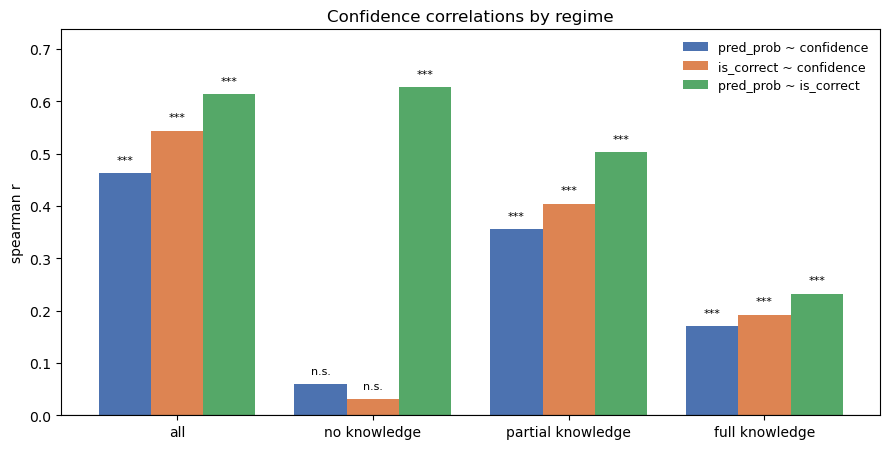

In [15]:
model_correct_by_run = model_vs_correctness_by_run(cc["predictions"])
display(model_correct_by_run[cols].round({"mean_x": 3, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))
D.plot_correlations_by_run(pd.concat([cc["correlations"], model_correct_by_run], ignore_index=True),
                           save=False);

With correctness held fixed instead (`pred_prob ~ confidence | is_correct`): the model against the
rating once what both share with being right is taken out. `n_wrong` is how many wrong answers the
run has.

,run,comparison,n,n_wrong,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,all,pred_prob ~ confidence | is_correct,1885,533,3.56,0.638,0.151,0.194,1.946850e-17
1,no knowledge,pred_prob ~ confidence | is_correct,625,393,2.06,0.439,0.050,0.052,1.963319e-01
2,partial knowledge,pred_prob ~ confidence | is_correct,620,124,3.87,0.663,0.234,0.192,1.462550e-06
3,full knowledge,pred_prob ~ confidence | is_correct,640,16,4.74,0.807,0.134,0.131,8.964185e-04


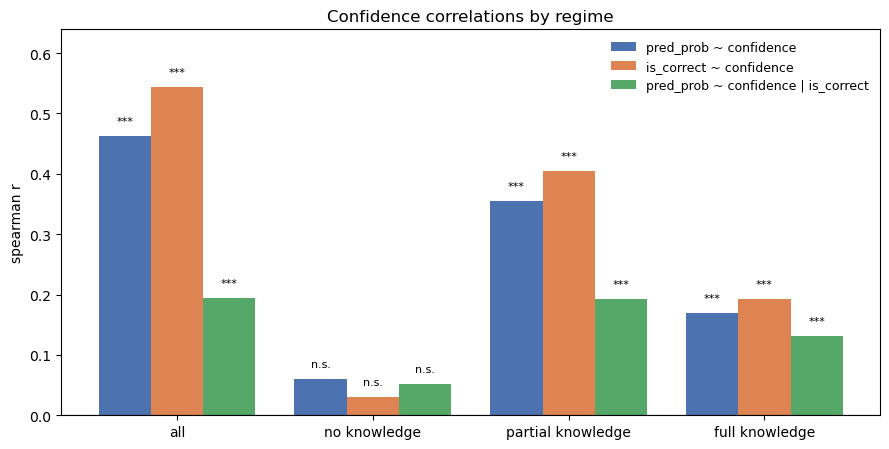

In [16]:
partial_by_run = partial_correlations_by_run(cc["predictions"])
display(partial_by_run[[*cols[:3], "n_wrong", *cols[3:]]]
        .round({"mean_x": 2, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))
D.plot_correlations_by_run(pd.concat([cc["correlations"], partial_by_run], ignore_index=True),
                           save=False);

### At each confidence rating

Per run and rating: how many trials, the model's mean predicted probability, and the participants'
actual accuracy. If the model tracks confidence, the two climb together down the scale.

In [17]:
cc["by_confidence"].round(3)

,run,confidence_rating,n,mean_pred_prob,median_pred_prob,std_pred_prob,accuracy,model_family
0,all,1,241,0.425,0.304,0.367,0.357,glmm
1,all,2,289,0.413,0.298,0.368,0.426,glmm
2,all,3,235,0.486,0.423,0.351,0.464,glmm
3,all,4,407,0.706,0.885,0.331,0.845,glmm
4,all,5,713,0.812,0.955,0.265,0.968,glmm
5,no knowledge,1,221,0.443,0.335,0.368,0.339,glmm
6,no knowledge,2,221,0.402,0.262,0.365,0.412,glmm
7,no knowledge,3,122,0.441,0.364,0.338,0.320,glmm
8,no knowledge,4,49,0.581,0.666,0.398,0.469,glmm
9,no knowledge,5,12,0.432,0.394,0.355,0.333,glmm


### Within each participant

`pred_prob ~ confidence` computed inside each person over all their trials, beside each person's
rating against their own correctness. The p-values are per person and uncorrected.

,participant_id,n,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,4000,145,3.54,0.792,0.575,0.539,2.574740e-12
1,4001,145,3.25,0.732,0.279,0.257,1.841241e-03
2,4002,145,3.40,0.545,0.289,0.294,3.249667e-04
3,4003,145,3.51,0.601,0.494,0.515,3.370636e-11
4,4004,145,3.34,0.493,0.571,0.582,1.550537e-14
5,4005,145,3.58,0.642,0.453,0.490,4.143190e-10
6,4006,145,3.88,0.616,0.460,0.499,1.624521e-10
7,4007,145,3.48,0.652,0.574,0.554,4.767275e-13
8,4008,145,3.90,0.571,0.496,0.495,2.366299e-10
9,4009,145,3.81,0.642,0.352,0.360,8.787627e-06


mean within-participant Spearman r: 0.490


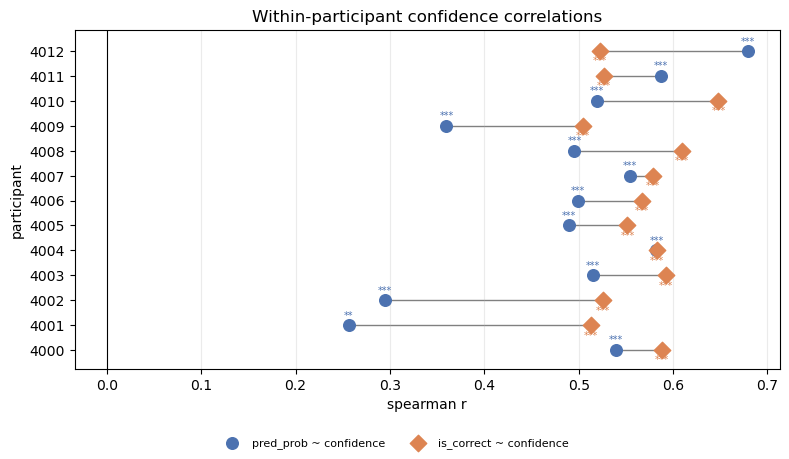

In [18]:
by_person = cc["by_participant"]
cols = ["participant_id", "n", "mean_x", "mean_y", "pearson_r", "spearman_r", "spearman_p"]
display(by_person[cols].round({"mean_x": 2, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))
print(f"mean within-participant Spearman r: {by_person['spearman_r'].mean():.3f}")

by_person_correct = correlations_by_participant(cc["predictions"], prob_col="is_correct")
D.plot_participant_correlation_forest(by_person, by_person_correct, save=False);

### Within each participant, by regime

The same series inside each regime separately, so the regime itself cannot drive the correlations.
Green, in turn: the model against correctness (`pred_prob ~ is_correct`), and the model against the
rating with correctness held fixed (`pred_prob ~ confidence | is_correct`). Under full knowledge
each person made only a few errors, so anything involving correctness there rests on a handful
of trials.

count   mean    min    max
comparison                          run                                          
pred_prob ~ confidence              no knowledge          13  0.160 -0.233  0.569
                                    partial knowledge     13  0.397  0.118  0.597
                                    full knowledge        13  0.200 -0.090  0.426
is_correct ~ confidence             no knowledge          13  0.083 -0.137  0.408
                                    partial knowledge     13  0.407  0.101  0.665
                                    full knowledge         8  0.279 -0.037  0.552
pred_prob ~ is_correct              no knowledge          13  0.636  0.306  0.814
                                    partial knowledge     13  0.501  0.306  0.601
                                    full knowledge         8  0.302  0.204  0.403
pred_prob ~ confidence | is_correct no knowledge          13  0.126 -0.223  0.565
                                    partial knowledge     13  0.236 -0.061  0.441
                                    full knowledge         8  0.114 -0.084  0.307

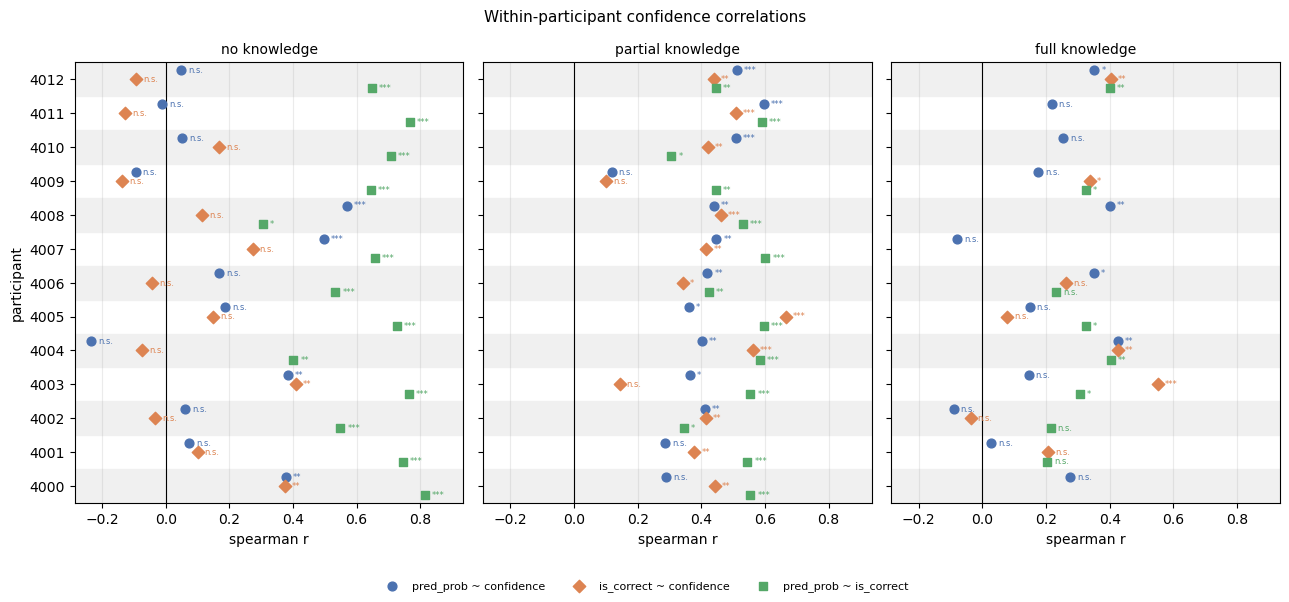

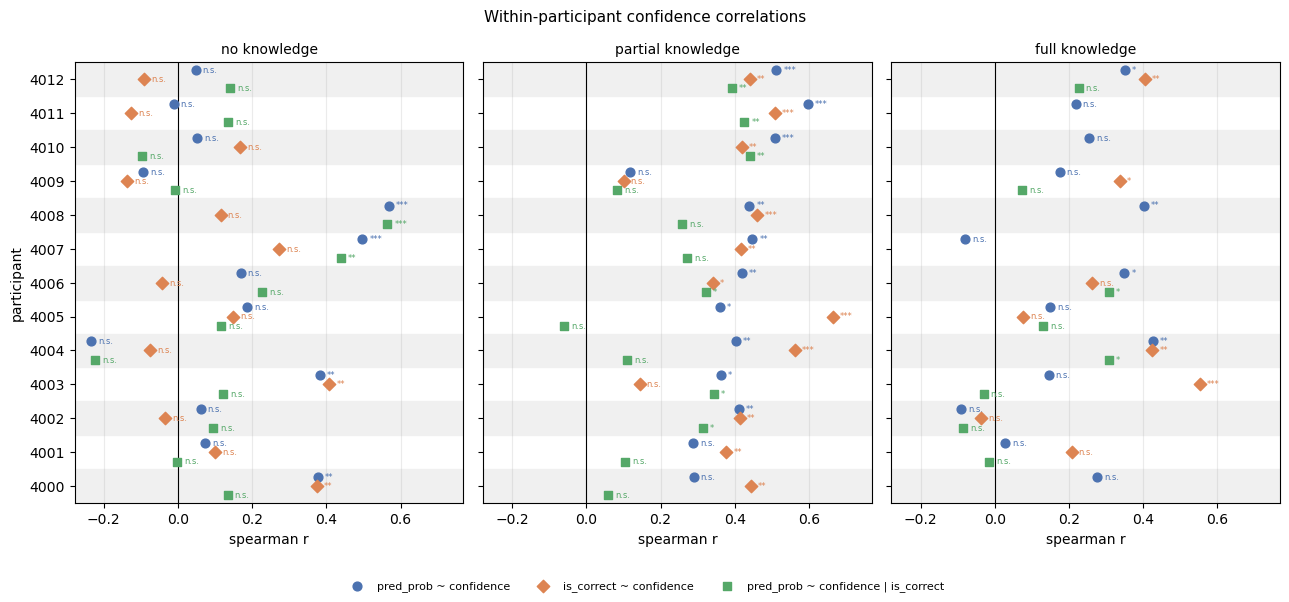

In [19]:
def per_regime(fn, **kwargs):
    # `fn`, one of the by-participant functions, run on each regime and stacked.
    return pd.concat([fn(cc["predictions"], run=r, **kwargs) for r in D.REGIME_ORDER],
                     ignore_index=True)


def summarise(frames):
    # Spearman r across participants, per comparison and regime; `count` is how many
    # participants have a value.
    return (pd.concat(frames, names=["comparison"]).reset_index(0)
            .groupby(["comparison", "run"], sort=False)["spearman_r"]
            .agg(["count", "mean", "min", "max"]).round(3))


regime_model = per_regime(correlations_by_participant)
regime_correct = per_regime(correlations_by_participant, prob_col="is_correct")
regime_model_correct = per_regime(correlations_by_participant, confidence_col="is_correct")
regime_partial = per_regime(partial_correlations_by_participant)
display(summarise({"pred_prob ~ confidence": regime_model,
                   "is_correct ~ confidence": regime_correct,
                   "pred_prob ~ is_correct": regime_model_correct,
                   "pred_prob ~ confidence | is_correct": regime_partial}))
D.plot_participant_correlation_forest(
    regime_model, regime_correct,
    third=regime_model_correct, third_label="pred_prob ~ is_correct", save=False,
)
D.plot_participant_correlation_forest(
    regime_model, regime_correct,
    third=regime_partial, third_label="pred_prob ~ confidence | is_correct", save=False,
);

## 4. Carrying the items' Study 1 intercepts into Study 2
*`TrialLevelJuliaGLMERModel(predict_with="known_levels")`*

What only the mixed model can do here. The participants are new, but every item was also answered in
Study 1, where the model estimated how hard it was (its random intercept). Scoring with
`known_levels` adds that intercept to each Study 2 trial; the participant's stays 0. It is the same
fitted model as above, scored a second way.

Read it with the regimes in mind. The item intercept is how hard the item was for Study 1 readers,
who had the paragraph. Under partial knowledge that is the same situation. Under no knowledge it is
not: how guessable an item is need not match how hard it is to answer from the text, so the
intercept may help there less, or mislead.

Study 2 trials whose item has a Study 1 intercept: 100%


,logreg,glmm_fixed,glmm_known_items
regime,,,
all,0.806,0.812,0.815
no knowledge,0.777,0.806,0.782
partial knowledge,0.774,0.785,0.839
full knowledge,0.861,0.857,0.901


glmm_fixed                  glmm_known_items                
                  mean_prob_correct mean_prob_wrong mean_prob_correct mean_prob_wrong
regime                                                                               
all                           0.785           0.263             0.781           0.243
no knowledge                  0.750           0.255             0.739           0.264
partial knowledge             0.755           0.292             0.750           0.178
full knowledge                0.822           0.244             0.823           0.209

glmm_fixed                             glmm_known_items                            
                   auc_model auc_confidence auc_combined        auc_model auc_confidence auc_combined
regime                                                                                               
all                    0.893          0.836        0.928            0.895          0.836        0.930
no knowledge           0.875          0.517        0.776            0.857          0.517        0.764
partial knowledge      0.863          0.777        0.881            0.913          0.777        0.903
full knowledge         0.929          0.757        0.918            0.936          0.757        0.921

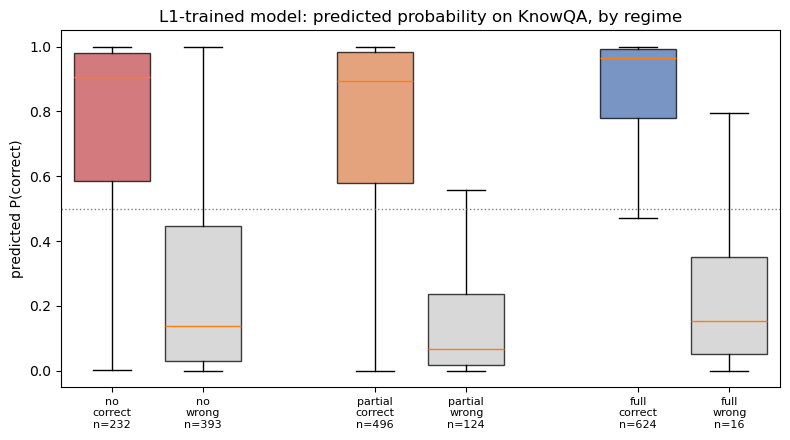

In [20]:
model.predict_with = "known_levels"
known = D.attach_predictions(df, model, verbose=False)
model.predict_with = "fixed"   # back to the scoring sections 1 to 3 use

items_known = known["text_id_with_q"].isin(l1["text_id_with_q"]).mean()
print(f"Study 2 trials whose item has a Study 1 intercept: {items_known:.0%}")

by = lambda frame: D.prediction_metrics_by_regime(frame).set_index(D.REGIME_COL)
display(pd.DataFrame({
    "logreg": by(logreg_scored)["balanced_accuracy"],
    "glmm_fixed": by(df)["balanced_accuracy"],
    "glmm_known_items": by(known)["balanced_accuracy"],
}).round(3))

prob = lambda frame: D.probability_by_regime(frame).set_index(D.REGIME_COL)
display(pd.concat({"glmm_fixed": prob(df)[["mean_prob_correct", "mean_prob_wrong"]],
                   "glmm_known_items": prob(known)[["mean_prob_correct", "mean_prob_wrong"]]},
                  axis=1).round(3))
display(pd.concat({"glmm_fixed": D.discrimination_comparison(df).set_index(D.REGIME_COL),
                   "glmm_known_items": D.discrimination_comparison(known).set_index(D.REGIME_COL)},
                  axis=1).filter(like="auc").round(3))
D.plot_probability_by_regime(known, save=False);